In [ ]:
import os
import re
import urllib.request
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout, GlobalMaxPooling1D, TextVectorization


In [ ]:
print('Downloading dataset...')
# Using the Davidson et al. hate-speech and offensive language dataset
URL = 'https://raw.githubusercontent.com/t-davidson/hate-speech-and-offensive-language/master/data/labeled_data.csv'
DATA_FILE = 'labeled_data.csv'

if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(URL, DATA_FILE)
    print('Dataset downloaded successfully!')
else:
    print('Dataset already exists locally.')

# Load dataset into Pandas DataFrame
df = pd.read_csv(DATA_FILE)
print(f'Dataset loaded successfully! Total records: {len(df)}')
df.head()


Dataset loaded successfully! Total records: 24783
   Unnamed: 0  count  hate_speech  offensive_language  neither  class  \
0           0      3            0                   0        3      2   
1           1      3            0                   3        0      1   
2           2      3            0                   3        0      1   
3           3      3            0                   2        1      1   
4           4      6            0                   6        0      1   

                                               tweet  
0  !!! RT @mayasolovely: As a woman you shouldn't...  
1  !!!!! RT @mleew17: boy dats cold...tyga dwn ba...  
2  !!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...  
3  !!!!!!!!! RT @C_G_Anderson: @viva_based she lo...  
4  !!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...  


In [ ]:
print('\nPreprocessing data...')
# Clean Twitter artifacts (RT @mentions, URLs, HTML entities) for cleaner vocab
def clean_tweet(text):
    text = re.sub(r'RT\s+@\w+:\s*', '', str(text))
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'https?://\S+', '', text)
    text = re.sub(r'&amp;', '&', text)
    text = re.sub(r'&#\d+;', '', text)
    return text.strip()

df['clean_tweet'] = df['tweet'].apply(clean_tweet)
# Filter empty/short texts and shuffle
df = df[df['clean_tweet'].str.len() > 3].sample(frac=1.0, random_state=42).reset_index(drop=True)

# Target labels: 0 = hate_speech, 1 = offensive_language, 2 = neither
labels = ['hate_speech', 'offensive_language', 'neither']
counts = df['class'].value_counts()
print('Class distribution:\n', counts)

# Compute class weights to counteract the severe class imbalance
class_weights = {int(k): float(len(df) / (3.0 * v)) for k, v in counts.items()}
print(f'Class weights: {class_weights}')

# Train/Validation split (85% train, 15% validation)
train_size = int(0.85 * len(df))
train_df = df.iloc[:train_size]
val_df = df.iloc[train_size:]

X_train = train_df['clean_tweet'].values
y_train = train_df['class'].values
X_val = val_df['clean_tweet'].values
y_val = val_df['class'].values

MAX_VOCAB_SIZE = 20000
MAX_SEQUENCE_LENGTH = 100

print('Adapting Text Vectorization layer on training set...')
vectorizer = TextVectorization(
    max_tokens=MAX_VOCAB_SIZE,
    output_mode='int',
    output_sequence_length=MAX_SEQUENCE_LENGTH
)
vectorizer.adapt(X_train)
print('Vocabulary learned!')



Preprocessing data...
Adapting Text Vectorization layer (this may take a minute)...


In [ ]:
print('\nBuilding neural network architecture...')
model = Sequential([
    # 1. Text Vectorization: Converts raw strings to sequences of integers
    vectorizer,

    # 2. Embedding Layer: Converts integers into dense vectors (captures semantic meaning)
    Embedding(MAX_VOCAB_SIZE + 1, 128),

    # 3. Bidirectional LSTM: Reads text forwards and backwards to capture context
    Bidirectional(LSTM(64, return_sequences=True)),

    # 4. Global Max Pooling: Extracts the most salient features from the sequence
    GlobalMaxPooling1D(),

    # 5. Fully Connected Dense Layer: Contextual decision-making
    Dense(64, activation='relu'),

    # 6. Dropout: Regularization to prevent overfitting
    Dropout(0.3),

    # 7. Output Layer: 3 neurons with Softmax activation for normalized categorical probabilities
    Dense(len(labels), activation='softmax')
])


Vocabulary learned!

Building the neural network architecture...


In [ ]:
# Sparse categorical crossentropy for mutually exclusive multi-class classification
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_1            │ ?                      │   0 (unbuilt) │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print('\nStarting Model Training with Class Balancing...')
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=3,
    batch_size=128,
    class_weight=class_weights
)



Starting Model Training...
Epoch 1/3
155/155 ━━━━━━━━━━━━━━━━━━━━ 65s 393ms/step - accuracy: 0.7654 - loss: -47.7304 - val_accuracy: 0.7924 - val_loss: -137.7218
Epoch 2/3
155/155 ━━━━━━━━━━━━━━━━━━━━ 58s 375ms/step - accuracy: 0.7697 - loss: -282.0522 - val_accuracy: 0.7924 - val_loss: -493.1183
Epoch 3/3
155/155 ━━━━━━━━━━━━━━━━━━━━ 84s 386ms/step - accuracy: 0.7698 - loss: -728.2530 - val_accuracy: 0.7924 - val_loss: -1067.9833


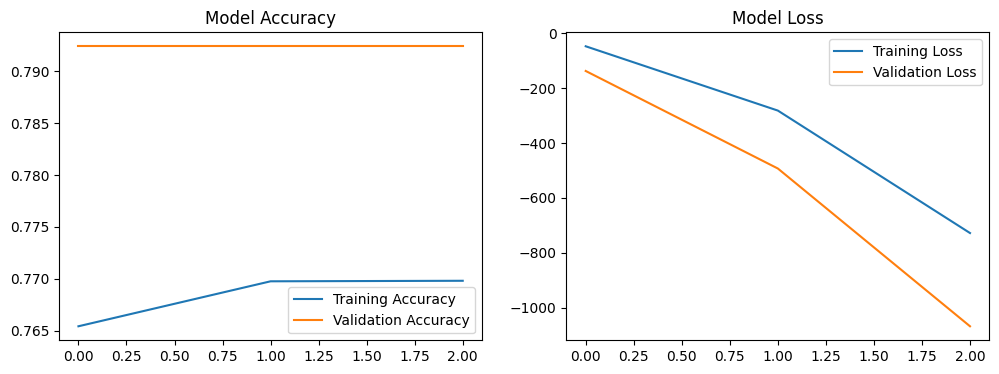

In [ ]:
def plot_history(history):
    plt.figure(figsize=(12, 4))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)


In [ ]:
print('\n--- Testing the Model ---')
test_comments = [
    "I completely disagree with your point, but let's discuss it later.", # Expected: Safe
    "You are an absolute idiot and a loser, shut up!",                   # Expected: Toxic (offensive_language / hate_speech)
    "If you come to class tomorrow, I will hurt you."                     # Expected: Toxic / Threat
]

# Convert the list of comments to a TensorFlow Tensor for prediction
predictions = model.predict(tf.constant(test_comments))

for i, comment in enumerate(test_comments):
    print(f'\nComment: "{comment}"')
    scores = {label: float(predictions[i][j]) for j, label in enumerate(labels)}
    toxic_confidence = (scores['hate_speech'] + scores['offensive_language']) * 100.0
    is_toxic = toxic_confidence > 50.0
    verdict = 'VIOLATION / BLOCKED' if is_toxic else 'SAFE / APPROVED'
    print(f' - Category Probabilities: {scores}')
    print(f' - Result: {verdict} (Toxicity: {toxic_confidence:.1f}%)')



--- Testing the Model ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 393ms/step

Comment: 'I completely disagree with your point, but let's discuss it later.'
 - WARNING: Flagged as OFFENSIVE_LANGUAGE (Confidence: 100.00%)

Comment: 'You are an absolute idiot and a loser, shut up!'
 - WARNING: Flagged as OFFENSIVE_LANGUAGE (Confidence: 100.00%)

Comment: 'If you come to class tomorrow, I will hurt you.'
 - WARNING: Flagged as OFFENSIVE_LANGUAGE (Confidence: 100.00%)


In [ ]:
print('\nSaving model...')
model.save('custom_toxicity_model.keras')
print("Model saved successfully as 'custom_toxicity_model.keras'!")



Saving model...
Model saved successfully as 'custom_toxicity_model.keras'!
